In [ ]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0


In [ ]:
!pip install git+https://github.com/andreinechaev/nvcc4jupyter.git

%load_ext nvcc4jupyter


  Cloning https://github.com/andreinechaev/nvcc4jupyter.git to /tmp/pip-req-build-yz2rebr2
  Running command git clone --filter=blob:none --quiet https://github.com/andreinechaev/nvcc4jupyter.git /tmp/pip-req-build-yz2rebr2
  Resolved https://github.com/andreinechaev/nvcc4jupyter.git to commit 28f872a2f99a1b201bcd0db14fdbc5a496b9bfd7
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for nvcc4jupyter: filename=nvcc4jupyter-1.2.1-py3-none-any.whl size=10741 sha256=90a829d54142cdbaf5703d6409de30ec0002408286cfbcd108dfdd84cf0ee4fe
  Stored in directory: /tmp/pip-ephem-wheel-cache-3ith3znj/wheels/7d/b9/66/459b9938664e6a93d1a85323ec52f7e51cd7265d253410a7d8
Successfully built nvcc4jupyter
Detected platform "Colab". Running its setup...
Source files will be saved in "/tmp/tmpup9weaa2".


### Hello world Program
- nvcc hello.cu -> to compile the code
- a.out -> to run the program

In [ ]:
%%cuda
#include <stdio.h>
#include <cuda.h>
__global__ void dkernel(){ //kernel
  printf("Hello World\n");
}
int main() {
    dkernel<<<1,1>>>(); //kernel launch
    cudaDeviceSynchronize(); // without this no output
    return 0;
}

Hello World



## Parallel processing

initial sequential cuda code

In [ ]:
%%cuda
#include <stdio.h>
#include <cuda.h>
# define N 100
__global__ void dkernel(){
  for (int i = 0; i < N; i++){
      printf("%d\n",i*i);
  }
}
int main(){
    dkernel<<<1,1>>>();
    cudaDeviceSynchronize();
    return 0;
}

0
1
4
9
16
25
36
49
64
81
100
121
144
169
196
225
256
289
324
361
400
441
484
529
576
625
676
729
784
841
900
961
1024
1089
1156
1225
1296
1369
1444
1521
1600
1681
1764
1849
1936
2025
2116
2209
2304
2401
2500
2601
2704
2809
2916
3025
3136
3249
3364
3481
3600
3721
3844
3969
4096
4225
4356
4489
4624
4761
4900
5041
5184
5329
5476
5625
5776
5929
6084
6241
6400
6561
6724
6889
7056
7225
7396
7569
7744
7921
8100
8281
8464
8649
8836
9025
9216
9409
9604
9801



parallelize the cuda processing

we access the thread id now to make it work parallel
- the problem are the output may not be ordered
- thread id always start with 0

In [ ]:
%%cuda
#include <stdio.h>
#include <cuda.h>
# define N 100
__global__ void dkernel(){
      printf("%d\n",threadIdx.x*threadIdx.x);
}
int main(){
    dkernel<<<1,N>>>();
    cudaDeviceSynchronize();
    return 0;
}

9216
9409
9604
9801
0
1
4
9
16
25
36
49
64
81
100
121
144
169
196
225
256
289
324
361
400
441
484
529
576
625
676
729
784
841
900
961
1024
1089
1156
1225
1296
1369
1444
1521
1600
1681
1764
1849
1936
2025
2116
2209
2304
2401
2500
2601
2704
2809
2916
3025
3136
3249
3364
3481
3600
3721
3844
3969
4096
4225
4356
4489
4624
4761
4900
5041
5184
5329
5476
5625
5776
5929
6084
6241
6400
6561
6724
6889
7056
7225
7396
7569
7744
7921
8100
8281
8464
8649
8836
9025



copying the array to GPU

In [ ]:
%%cuda
#include <stdio.h>
#include <cuda.h>
# define N 100
__global__ void dkernel(int *a) {
    a[threadIdx.x] = threadIdx.x *threadIdx.x;
}

int main(){
    int a[N], *d_a;
    cudaMalloc(&d_a, N*sizeof(int));
    dkernel<<<1,N>>>(d_a);
    cudaDeviceSynchronize();
    cudaMemcpy(a, d_a, N*sizeof(int), cudaMemcpyDeviceToHost);
    for(int i = 0; i < N;i++){
        printf("%d ", a[i]);
        if (i % 10 == 0 && i != 0)
          printf("\n");
    }
    cudaFree(d_a);
    return 0;
}

0 1 4 9 16 25 36 49 64 81 100 
121 144 169 196 225 256 289 324 361 400 
441 484 529 576 625 676 729 784 841 900 
961 1024 1089 1156 1225 1296 1369 1444 1521 1600 
1681 1764 1849 1936 2025 2116 2209 2304 2401 2500 
2601 2704 2809 2916 3025 3136 3249 3364 3481 3600 
3721 3844 3969 4096 4225 4356 4489 4624 4761 4900 
5041 5184 5329 5476 5625 5776 5929 6084 6241 6400 
6561 6724 6889 7056 7225 7396 7569 7744 7921 8100 
8281 8464 8649 8836 9025 9216 9409 9604 9801 


- Each Thread assigns zero to its corresponding array index with respect to its thread ID

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 32

__global__ void init(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] = 0;
}

int main(){
    int *da;
    int a[N];
    cudaMalloc(&da,N*sizeof(int));
    init<<<1,32>>>(da,N);
    cudaDeviceSynchronize();
    cudaMemcpy(a,da,N*sizeof(int),cudaMemcpyDeviceToHost);
    for(int i = 0; i < N;i++)
      printf("%d ",a[i]);
    printf("\n");
    return 0;
}

0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 



- Write a CUDA program to initialize an array of size 32 to all zeros in parallel
- change the array size to 1024
- create another kernel that adds i to array[i].
- change the array size to 8000

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 1024

__global__ void init(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] = 0;
}
__global__ void add(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] += id;
}

int main(){
    int *da;
    int a[N];
    cudaMalloc(&da,N*sizeof(int));
    init<<<1,1024>>>(da,N);
    add<<<1,1024>>>(da,N);
    cudaDeviceSynchronize();
    cudaMemcpy(a,da,N*sizeof(int),cudaMemcpyDeviceToHost);
    for(int i = 0; i < N;i++){
      printf("%d ",a[i]);
      if (i % 100 == 0)
        printf("\n");
    }
    return 0;
}

0 
1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 
101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199 200 
201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239 240 241 242 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257 258 259 260 261 262 263 264 265 266 267 268 269 270 271 272 273 274 275 276

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 8000

__global__ void init(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] = 0;
}
__global__ void add(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] += id;
}

int main(){
    int *da;
    int a[N];
    cudaMalloc(&da,N*sizeof(int));
    init<<<1,N>>>(da,N);
    add<<<1,N>>>(da,N);
    cudaDeviceSynchronize();
    cudaMemcpy(a,da,N*sizeof(int),cudaMemcpyDeviceToHost);
    for(int i = 0; i < N;i++){
      printf("%d ",a[i]);
      if (i % 100 == 0)
        printf("\n");
    }
    return 0;
}

0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0

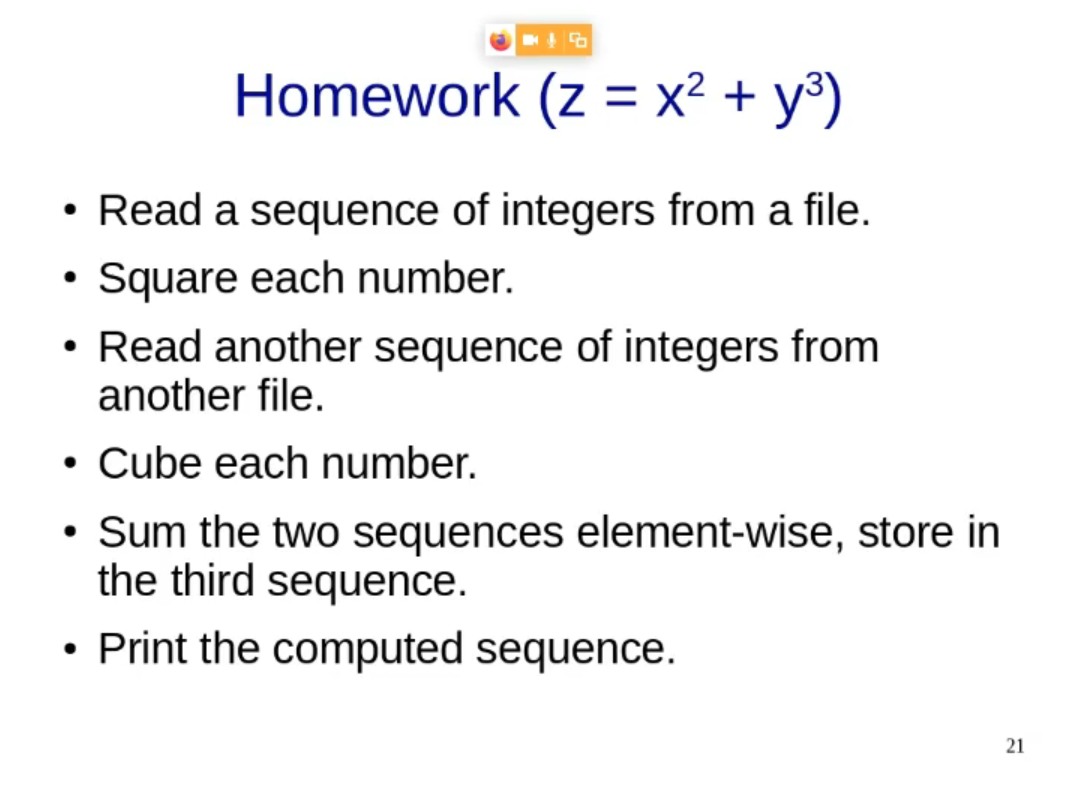

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 10

__global__ void cube(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] = id*id*id;
}
__global__ void square(int *a,int alen){
    unsigned id= threadIdx.x;
    if(id < alen)
      a[id] = id*id;
}
__global__ void add(int *a,int *b){
    unsigned id= threadIdx.x;
    a[id] = a[id] +b[id];
}

int main(){
    int *da,*db;
    int a[N];
    cudaMalloc(&da,N*sizeof(int));
    square<<<1,N>>>(da,N);
    cudaMalloc(&db,N*sizeof(int));
    cube<<<1,N>>>(db,N);
    add<<<1,N>>>(da,db);
    cudaDeviceSynchronize();
    cudaMemcpy(a,da,N*sizeof(int),cudaMemcpyDeviceToHost);
    for(int i = 0; i < N;i++){
      printf("%d ",a[i]);
      if (i % 100 == 0)
        printf("\n");
    }
    return 0;
}

0 
2 12 36 80 150 252 392 576 810 


In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>

__global__ void dkernel(){
    if(threadIdx.x == 0 && blockIdx.x == 0 &&
       threadIdx.y == 0 && blockIdx.y == 0 &&
       threadIdx.z == 0 && blockIdx.z == 0){
           printf("%d %d %d %d %d %d",gridDim.x,gridDim.y,gridDim.z,blockDim.x,blockDim.y,blockDim.z);
       }
}
int main(){
    dim3 grid(2,3,4);
    dim3 block(5,6,7);
    dkernel<<<grid,block>>>();
    cudaDeviceSynchronize();
    return 0;
}

2 3 4 5 6 7


## 1D Matrix

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 5
#define M 6
__global__ void dkernel(unsigned *a){
    unsigned id = blockDim.x*blockIdx.x +threadIdx.x;
    a[id] = id;
}
int main(){
    unsigned *gmatrix,*cmatrix;
    cudaMalloc(&gmatrix,N*M*sizeof(unsigned));
    cmatrix = (unsigned*)malloc(N*M*sizeof(unsigned));
    dkernel<<<N,M>>>(gmatrix);
    cudaMemcpy(cmatrix,gmatrix,N*M*sizeof(unsigned),cudaMemcpyDeviceToHost);
    for(unsigned ii = 0;ii < N; ++ii){
        for(unsigned jj = 0;jj < M; ++jj){
            printf("%2d ",cmatrix[ii*M+jj]);
        }
        printf("\n");
    }
    return 0;
}

 0  1  2  3  4  5 
 6  7  8  9 10 11 
12 13 14 15 16 17 
18 19 20 21 22 23 
24 25 26 27 28 29 



## 2D Matrix

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define N 5
#define M 6
__global__ void dkernel(unsigned *a){
    unsigned id = blockDim.y*threadIdx.x +threadIdx.y;
    a[id] = id ;
}
int main(){
    dim3 block(N,M,1);
    unsigned *gmatrix,*cmatrix;
    cudaMalloc(&gmatrix,N*M*sizeof(unsigned));
    cmatrix = (unsigned*)malloc(N*M*sizeof(unsigned));
    dkernel<<<1,block>>>(gmatrix);
    cudaMemcpy(cmatrix,gmatrix,N*M*sizeof(unsigned),cudaMemcpyDeviceToHost);
    for(unsigned ii = 0;ii < N; ++ii){
        for(unsigned jj = 0;jj < M; ++jj){
            printf("%2d ",cmatrix[ii*M+jj]);
        }
        printf("\n");
    }
    return 0;
}

 0  1  2  3  4  5 
 6  7  8  9 10 11 
12 13 14 15 16 17 
18 19 20 21 22 23 
24 25 26 27 28 29 



## Launch Configuration for Huge Data in runtime

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define blocksize 1024
__global__ void dkernel(unsigned *vector,unsigned vectorsize){
    unsigned id = blockIdx.x*blockDim.x + threadIdx.x;
    if (id < vectorsize)
    //this if is used to avoid out of memory access
    //like N can be 1000 but 1024 threads can be created to avoid remaining 24 threads from writing
      vector[id] = id;
}

int main(int nn, char *str[]){
    unsigned N = atoi(str[1]);
    unsigned *gvector,*cvector;
    cudaMalloc(&gvector,N*sizeof(unsigned));
    cvector = (unsigned*)malloc(N*sizeof(unsigned));
    unsigned nblocks = ceil((float)N/blocksize);
    printf("nblocks = %d\n",nblocks);
    dkernel<<<nblocks,blocksize>>>(gvector,N);
    cudaMemcpy(cvector,gvector,N*sizeof(unsigned),cudaMemcpyDeviceToHost);
    for(unsigned ii = 0; ii < N;ii++)
        printf("%4d",cvector[ii]);
    return 0;
}

## Matrix Squaring

In [ ]:
# Cpu version
void squarecpu(unsigned *matrix, unsigned *result, unsigned matrixsize) {
	for (unsigned ii = 0; ii < matrixsize; ++ii) {
	for (unsigned jj = 0; jj < matrixsize; ++jj) {
		for (unsigned kk = 0; kk < matrixsize; ++kk) {
			result[ii * matrixsize + jj] += matrix[ii * matrixsize + kk] * matrix[kk * matrixsize + jj];
		}
	}
	}


(Version - 1) we parllelize i loop  

In [ ]:
__global__ void square(unsigned *matrix, unsigned *result, unsigned matrixsize) {
	unsigned id = blockIdx.x * blockDim.x + threadIdx.x;
	for (unsigned jj = 0; jj < matrixsize; ++jj) {
		for (unsigned kk = 0; kk < matrixsize; ++kk) {
			result[id * matrixsize + jj] += matrix[id * matrixsize + kk] * matrix[kk * matrixsize + jj];
		}
	}
}

square <<<1,N>>>(matrix,result,N);


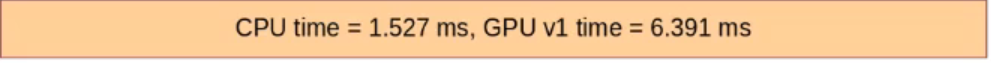

overhead is result of kernel launch

(version - 2)

In [ ]:
__global__ void square(unsigned *matrix, unsigned *result, unsigned matrixsize) {
	unsigned id = blockIdx.x * blockDim.x + threadIdx.x;
	unsigned ii = id / matrixsize; //slowly changing
	unsigned jj = id % matrixsize; //faster changing
	for (unsigned kk = 0; kk < matrixsize; ++kk) {
		result[ii * matrixsize + jj] += matrix[ii * matrixsize + kk] * matrix[kk * matrixsize + jj];
	}
}

square <<<N,N>>>(matrix,result,N);


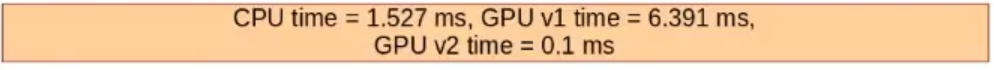

In square matrix the ii and jj value can be interchanged in version 2 then we need to change the computation of result to different else we may get a slower output and the result will also be a transpose of the original result

## Warp with conditions


- all threads in warp start executing the usigned id line
- if block only by odd id threads where even id threads are stalled
- in next cycle the else block is executed where the odd id threads are stalled

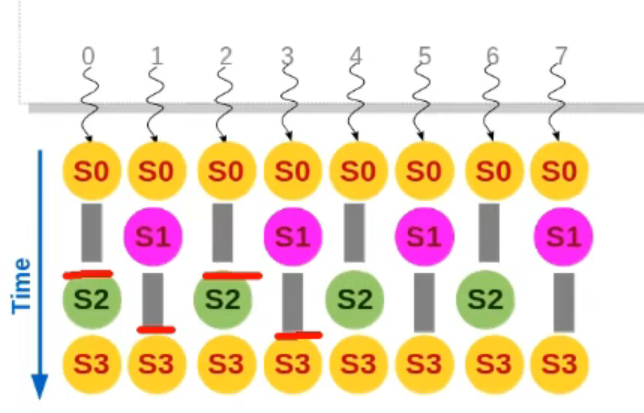

In [ ]:
__global__ void dkernel(unsigned *vector,unsigned vectorsize){
    unsigned id = blockIdx.x*blockDim.x + threadIdx.x; // s0
    if(id % 2) //s1
      vector[id] = id;
    else //s3
      vector[id] = vectorsize*vectorsize;
    vector[id]++; //s4
}

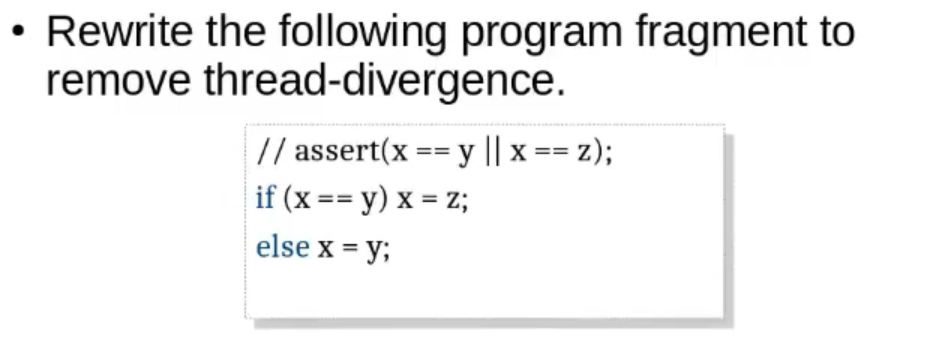

In [ ]:
x = y + z - x
// if  x = y then x = x + z - x then x = z
// if x = z then x = y + x - x then x = y